# GFMO: Grid Foundation Model (GENCO)–Embedded Optimization for AC-Feasible Unit Commitment

## 1. Mathematical formulation

The mathematical formulation is given in the [Hugging Face submission](https://huggingface.co/spaces/gridfm/genco-challenge/discussions/34).


## 2. GENCO configuration

In [1]:
MODEL_SIZE = "base"  # "small" or "base"
SEED = 0  # 0 or 1


## 3. Network and environment setup

The notebook includes the source and case. It downloads the matching GENCO checkpoint and normalization data automatically. Automatic installation requires Python 3.11 on Linux x86_64.

In [2]:
# Included source archive; expand this cell to inspect the extraction code.
import base64, hashlib, io, json, os, pathlib, subprocess, sys, zipfile

WORK = pathlib.Path.cwd() / "gfmo_demo"
payload = base64.b64decode(
    "..."
)
assert (
    hashlib.sha256(payload).hexdigest()
    == "ab32f3fc454fb7eb47aa2390158fa8d2f96e2041350084cf187fd6b0a288b2fc"
)
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for item in archive.infolist():
        relative = pathlib.PurePosixPath(item.filename)
        if relative.is_absolute() or ".." in relative.parts:
            raise ValueError("Unsafe source path")
        target = WORK / str(relative)
        data = archive.read(item)
        if target.exists() and target.read_bytes() != data:
            raise ValueError(
                f"Existing source differs: {target}. Use a fresh work directory."
            )
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(data)
print("Source and case ready.")


Source and case ready.


In [3]:
import importlib.util
from IPython.display import display, ProgressBar, SVG

spec = importlib.util.spec_from_file_location(
    "gfmo_setup", WORK / "scripts/setup_environment.py"
)
setup = importlib.util.module_from_spec(spec)
spec.loader.exec_module(setup)
progress = ProgressBar(3)
display(progress)
setup_status = display("Preparing CPU environment…", display_id=True)


def advance(step, label):
    progress.progress = step
    setup_status.update(label)


PYTHON = setup.environment(progress=advance)
setup_status.update("Checking GENCO weights, normalization data and network…")
with (WORK / "setup.log").open("a") as log:
    subprocess.run(
        [
            PYTHON,
            str(WORK / "scripts/setup_environment.py"),
            "--size",
            MODEL_SIZE,
            "--seed",
            str(SEED),
        ],
        check=True,
        stdout=log,
        stderr=subprocess.STDOUT,
    )
    subprocess.run(
        [
            PYTHON,
            "-c",
            "import sys; sys.path.insert(0,'src'); import genco_model, ac_subproblem, decomposition",
        ],
        cwd=WORK,
        env=dict(os.environ, MPLBACKEND="Agg"),
        check=True,
        stdout=log,
        stderr=subprocess.STDOUT,
    )
progress.progress = 3
setup_status.update("Setup complete")
print("GENCO", MODEL_SIZE, "· seed", SEED, "· IEEE 57 ready")


[                                                            ] 0/3

'Setup complete'

GENCO base · seed 0 · IEEE 57 ready


## 4. Embedded optimization

A fresh run has a 300-second search budget. The bar shows elapsed time, not convergence. Installation and downloads are outside the clock.

[                                                            ] 0/300

'Solve complete · checking the full UC–ACOPF schedule'

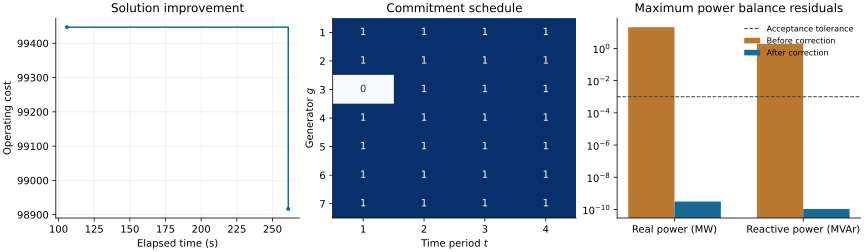

AC-feasible UC schedule: True
Time to first feasible schedule (s): 105.8637830830121
Total computation time (s): 301.42
Operating cost: 98916.843278571


In [4]:
import time, signal, uuid

budget = 300
elapsed = ProgressBar(budget)
display(elapsed)
solve_status = display(
    "Loading GENCO and initializing the UC schedule…", display_id=True
)
live_plot = display("The first feasible schedule will appear here.", display_id=True)
last_plot = None
marker = WORK / (".progress_" + uuid.uuid4().hex + ".json")
run_env = dict(
    os.environ,
    GFMO_DEMO_PROGRESS_FILE=str(marker),
    MPLBACKEND="Agg",
    MPLCONFIGDIR=str(WORK / ".cache/matplotlib"),
    XDG_CACHE_HOME=str(WORK / ".cache"),
)
started = time.monotonic()
with (WORK / "notebook_solve.log").open("w") as log:
    process = subprocess.Popen(
        [
            PYTHON,
            str(WORK / "scripts/run_example.py"),
            "--size",
            MODEL_SIZE,
            "--seed",
            str(SEED),
            "--seconds",
            str(budget),
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True,
        env=run_env,
    )
    try:
        while process.poll() is None:
            elapsed.progress = min(budget, int(time.monotonic() - started))
            if marker.exists():
                try:
                    current = pathlib.Path(json.loads(marker.read_text())["folder"])
                    report = json.loads((current / "solver.json").read_text())
                    completed = sum(
                        c.get("phase") == "initialization"
                        and c.get("status") == "accepted corrected feasibility point"
                        for c in report.get("calls", [])
                    )
                    phase = (
                        f"GENCO + AC correction · {completed}/4 periods initialized"
                        if report["status"] == "initializing"
                        else f"UC coordination + input optimization · {len(report.get('history', []))} iterations"
                    )
                    best = report.get("best")
                    feasible = (
                        "no feasible schedule yet"
                        if best is None
                        else f"best cost {best['objective']:,.2f}"
                    )
                    solve_status.update(
                        f"{int(time.monotonic()-started)} s · {phase} · {feasible}"
                    )
                    if best is not None and best["accepted_at_s"] != last_plot:
                        figure = current / "progress.svg"
                        plot = subprocess.run(
                            [
                                PYTHON,
                                str(WORK / "scripts/plot_results.py"),
                                str(current / "solver.json"),
                                str(figure),
                            ],
                            env=run_env,
                            stdout=log,
                            stderr=subprocess.STDOUT,
                        )
                        if plot.returncode == 0:
                            live_plot.update(SVG(filename=str(figure)))
                            last_plot = best["accepted_at_s"]
                except (FileNotFoundError, json.JSONDecodeError):
                    pass
            time.sleep(1)
    except KeyboardInterrupt:
        try:
            os.killpg(process.pid, signal.SIGTERM)
        except ProcessLookupError:
            pass
        try:
            process.wait(timeout=5)
        except subprocess.TimeoutExpired:
            pass
        try:
            os.killpg(process.pid, signal.SIGKILL)
        except ProcessLookupError:
            pass
        process.wait()
        raise
if process.returncode:
    raise RuntimeError((WORK / "notebook_solve.log").read_text()[-4000:])
run_folder = pathlib.Path(json.loads((WORK / "latest_run.json").read_text())["folder"])
summary = json.loads((run_folder / "summary.json").read_text())
solve_status.update("Solve complete · checking the full UC–ACOPF schedule")
print("AC-feasible UC schedule:", summary["accepted"])
print("Time to first feasible schedule (s):", summary["first_feasible_s"])
print("Total computation time (s):", round(summary["process_elapsed_s"], 2))
print("Operating cost:", summary.get("objective", "—"))


## 5. Feasibility verification

The plots show the current best schedule. The residual comparison evaluates
GENCO predictions at the selected input values and their corrected outputs
against the original physical network.

The checker recomputes all original UC–ACOPF constraints. Tolerances:
$10^{-3}$ MW/MVAr/MVA, $10^{-5}$ p.u., $10^{-6}$ rad; exact binary decisions.


In [5]:
if summary["accepted"]:
    witness = json.loads((run_folder / "witness.json").read_text())
    print("Online indicators (rows: periods; columns: generators)")
    for row in witness["u"]:
        print(" ".join(str(int(v)) for v in row))
    print("\nMaximum constraint violations")
    labels = {
        "line_mva": "Transmission limit (MVA)",
        "angle_relation_rad": "Voltage-angle relation (rad)",
        "p_bounds_mw": "Real generation bounds (MW)",
        "q_bounds_mvar": "Reactive generation bounds (MVAr)",
        "initial_obligations": "Initial commitment",
        "minimum_up": "Minimum up time",
        "minimum_down": "Minimum down time",
        "ramp_up_mw": "Ramp up (MW)",
        "ramp_down_mw": "Ramp down (MW)",
        "p_balance_mw": "Real power balance (MW)",
        "q_balance_mvar": "Reactive power balance (MVAr)",
        "voltage_pu": "Voltage magnitude bounds (p.u.)",
        "reference_rad": "Reference angle (rad)",
        "transition": "Commitment logic",
    }
    for name, value in summary["ac_constraints"]["max_violations"].items():
        print(f"{labels[name]:36s} {value:.3e}")
else:
    print(
        "No feasible schedule found within the budget. See solver.log and solver.json."
    )


Online indicators (rows: periods; columns: generators)
1 1 0 1 1 1 1
1 1 1 1 1 1 1
1 1 1 1 1 1 1
1 1 1 1 1 1 1

Maximum constraint violations
Transmission limit (MVA)             0.000e+00
Voltage-angle relation (rad)         1.388e-17
Real generation bounds (MW)          0.000e+00
Reactive generation bounds (MVAr)    2.556e-20
Initial commitment                   0.000e+00
Minimum up time                      0.000e+00
Minimum down time                    0.000e+00
Ramp up (MW)                         0.000e+00
Ramp down (MW)                       0.000e+00
Real power balance (MW)              3.099e-10
Reactive power balance (MVAr)        1.083e-10
Voltage magnitude bounds (p.u.)      0.000e+00
Reference angle (rad)                0.000e+00
Commitment logic                     0.000e+00


## References and data

[GENCO models](https://huggingface.co/gridfm/genco-opf-datakit) · [IEEE57 data](https://huggingface.co/datasets/gridfm/opf_small_case57_ieee) · [Graphkit](https://github.com/gridfm/gridfm-graphkit)

The IEEE57 instance extends scenario 308 over four periods. The UC–ACOPF
constraints include nonnegative reactive generation and the principal angle branch.
See LICENSE and LICENSES/THIRD_PARTY_NOTICES.md in the extracted source folder.
